In [1]:
import sys
sys.path.append("..")

from src.data import load_brent_spot, load_brent_futures
from src.models import random_walk_forecast
from src.backtest import walk_forward

<Axes: xlabel='DATE'>

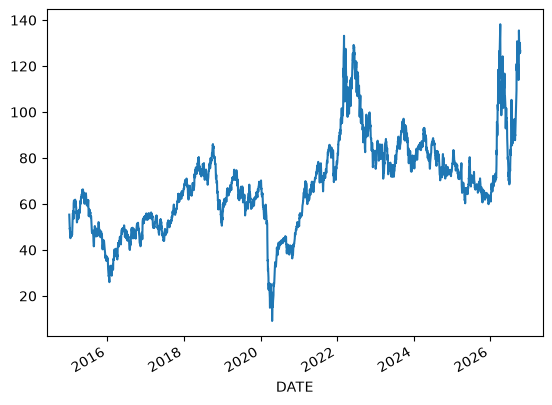

In [ ]:
spot = load_brent_spot(start="2015-01-01")
spot.tail()
spot["brent_spot"].plot()

<Axes: xlabel='Date'>

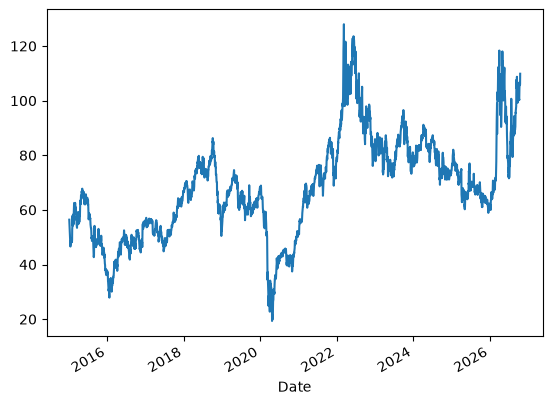

In [2]:
futures = load_brent_futures(start="2015-01-01")
futures.tail()
futures["brent_futures"].plot()

<Axes: xlabel='DATE'>

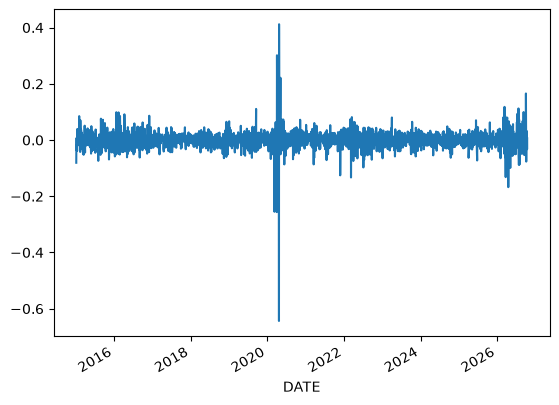

In [5]:
from src.features import log_returns

returns = log_returns(spot)
returns.plot()

In [4]:
spot = load_brent_spot(start="2015-01-01")

results = walk_forward(
    spot["brent_spot"],
    horizon=1,
    start_date="2024-01-01",
    end_date="2026-09-30",
    forecast_funct=random_walk_forecast,
)

results.head()

,origin_date,target_date,forecast,actual
0,2024-01-02,2024-01-03,76.24,77.18
1,2024-01-03,2024-01-04,77.18,75.79
2,2024-01-04,2024-01-05,75.79,78.31
3,2024-01-05,2024-01-08,78.31,75.47
4,2024-01-08,2024-01-09,75.47,77.97


In [6]:
errors = results["actual"] - results['forecast']
mae = errors.abs().mean()
rmse = (errors ** 2).mean() ** 0.5
print(f"MAE: {mae:.3f}, RMSE: {rmse:.3f}")

MAE: 1.604, RMSE: 2.574
